# Treći dio projekta iz Uvod u znanost o podacima (UUZOP)

Članovi: Karla Budimir, Mateo Jakšić, Ana Knezović

Napomena: Priprema dataseta je uzeta od Karle Budimir. Podaci su uvezeni kao .csv datoteke.

In [24]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, cross_val_predict, GridSearchCV
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, f1_score

In [25]:
import warnings
warnings.filterwarnings('ignore')

### Podjela podataka

U ovim primjerima koristit ćemo dva različita pristupa podjeli podataka. U primjerima pod A, koristi se skup podataka gdje ciljna varijabla ostaje neizmijenjena, dok u primjerima pod B ciljnoj varijabli dodjeljujemo vrijednost 1 tamo gdje je "num" različit od 0. 

Decision Tree, Naive Bayes i Random Forest nisu osjetljivi na skalu tj. feature scaling pa ćemo za njih koristiti nestandardizirane podatke. Za Logistic Regression i SVM koristimo standardizirane podatke.

Prenaučenost ćemo spriječiti podešavajući hiperparametre.

In [26]:
# Uvoz podataka
df_encoded = pd.read_csv("heart_failure_train_ready.csv", index_col = 0)
df_standardized = pd.read_csv("heart_failure_train_ready_standard.csv", index_col = 0)

# Originalne značajke i ciljna varijabla
X = df_encoded.iloc[:, :-1]
y = df_encoded.iloc[:, -1]

# Set A - podjela podataka bez promjena ciljne varijable
X_train1, X_test1, y_train1, y_test1 = train_test_split(X, y, test_size=0.15, random_state=42)

# Binarizacija ciljne varijable za set B
y_bin = (y != 0).astype(int)

# Set B - podjela podataka s binarnom ciljnom varijablom
X_train2, X_test2, y_train2, y_test2 = train_test_split(X, y_bin, test_size=0.15, random_state=42)

# Originalne značajke i ciljna varijabla
X_standardized = df_standardized.iloc[:, :-1]
y_standardized = df_encoded.iloc[:, -1]

# Set A - podjela podataka bez promjena ciljne varijable
X_train3, X_test3, y_train3, y_test3 = train_test_split(X_standardized, y_standardized, test_size=0.15, random_state=42)

# Binarizacija ciljne varijable za set B
y_bin_standardized = (y_standardized != 0).astype(int)

# Set B - podjela podataka s binarnom ciljnom varijablom
X_train4, X_test4, y_train4, y_test4 = train_test_split(X_standardized, y_bin_standardized, test_size=0.15, random_state=42)


### Decision Tree

In [27]:
from sklearn.tree import DecisionTreeClassifier

# Inicijalizacija modela
dtc1 = DecisionTreeClassifier()
dtc2 = DecisionTreeClassifier()

# Model treniran na originalnim podacima (set A)
dtc1.fit(X_train1, y_train1)
y_pred1 = dtc1.predict(X_test1)

# Model treniran na binarnim podacima (set B)
dtc2.fit(X_train2, y_train2)
y_pred2 = dtc2.predict(X_test2)

# Ispis točnosti
print(f"Accuracy za SET A: {accuracy_score(y_test1, y_pred1)}")
print(f"Accuracy za SET B: {accuracy_score(y_test2, y_pred2)}")

Accuracy za SET A: 0.5111111111111111
Accuracy za SET B: 0.6444444444444445


Decision Tree - SET A

               precision    recall  f1-score   support

           0       0.86      0.66      0.75        29
           1       0.08      0.25      0.12         4
           2       0.00      0.00      0.00         5
           3       0.38      0.50      0.43         6
           4       0.00      0.00      0.00         1

    accuracy                           0.51        45
   macro avg       0.26      0.28      0.26        45
weighted avg       0.61      0.51      0.55        45



Decision Tree - SET B

               precision    recall  f1-score   support

           0       0.81      0.59      0.68        29
           1       0.50      0.75      0.60        16

    accuracy                           0.64        45
   macro avg       0.65      0.67      0.64        45
weighted avg       0.70      0.64      0.65        45





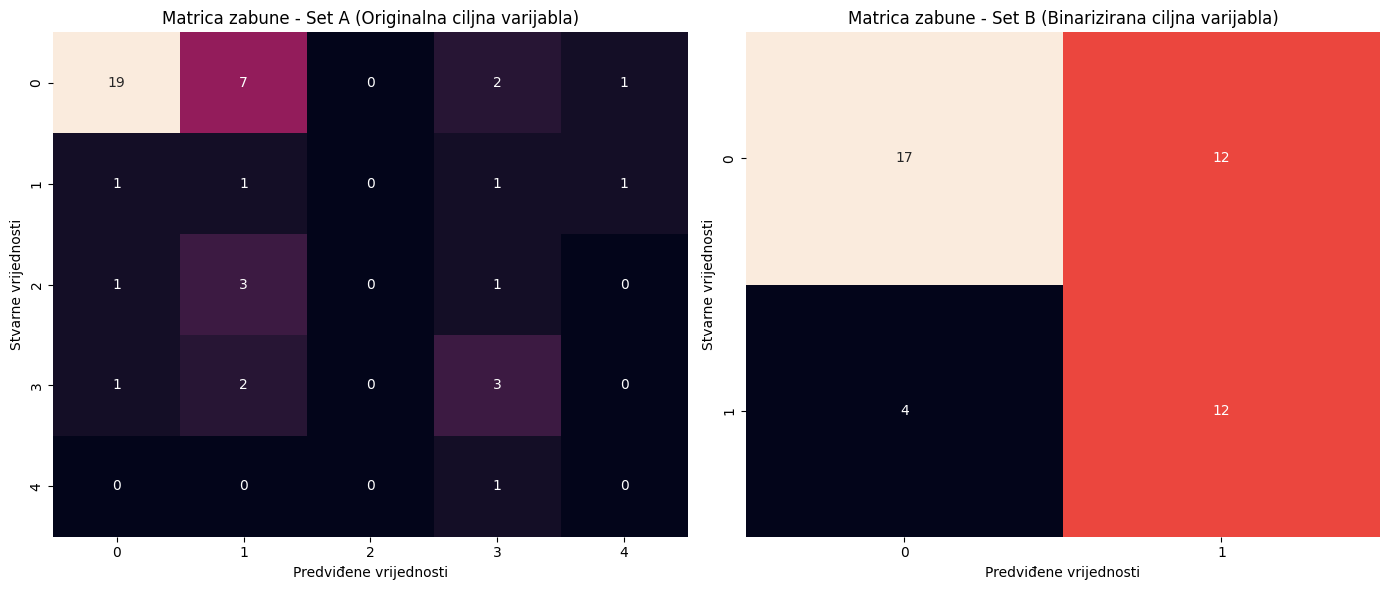

In [28]:
# Ispis izvještaja
print(f"Decision Tree - SET A\n\n {classification_report(y_test1, y_pred1)}\n\n")
print(f"Decision Tree - SET B\n\n {classification_report(y_test2, y_pred2)}\n\n")

# Matrice zabune za oba seta
cm_dtc1 = confusion_matrix(y_test1, y_pred1)
cm_dtc2 = confusion_matrix(y_test2, y_pred2)

# Postavka za subplots (dva reda)
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Plot matrice zabune za Set A
sns.heatmap(cm_dtc1, annot=True, fmt='d', cbar=False, ax=axes[0])
axes[0].set_title('Matrica zabune - Set A (Originalna ciljna varijabla)')
axes[0].set_xlabel('Predviđene vrijednosti')
axes[0].set_ylabel('Stvarne vrijednosti')

# Plot matrice zabune za Set B
sns.heatmap(cm_dtc2, annot=True, fmt='d', cbar=False, ax=axes[1])
axes[1].set_title('Matrica zabune - Set B (Binarizirana ciljna varijabla)')
axes[1].set_xlabel('Predviđene vrijednosti')
axes[1].set_ylabel('Stvarne vrijednosti')

plt.tight_layout()
plt.show()

In [29]:
# Ispis važnosti značajki
features = pd.DataFrame(dtc2.feature_importances_, index = X.columns)
features.head(15)

,0
sex,0.028494
cp,0.294048
trestbps,0.027363
chol,0.136471
fbs,0.021480
restecg,0.022462
thalch,0.115589
exang,0.062604
oldpeak,0.033394
slope,0.043894


In [30]:
# Ispis distribucije ciljnih varijabli
class_distribution = pd.Series(y).value_counts()
print(class_distribution)

num
0    159
1     54
2     35
3     35
4     13
Name: count, dtype: int64


In [31]:
# Ispis omjera neravnoteže
largest_class = class_distribution.max()
smallest_class = class_distribution.min()
imbalance_ratio = largest_class / smallest_class

print(f"Omjer neravnoteže: {imbalance_ratio}")

Omjer neravnoteže: 12.23076923076923


Vidimo da imamo nebalansirane podatke... većinska klasa 0 ima oko 12 puta više uzoraka od klase 4 koja je najmanje zastupljena. Sad ćemo se fokusirati na SET B tj. binarnu klasifikaciju i pokušat ćemo poboljšati model gridsearchom s krosvalidacijom.

In [32]:
# Ispis parametara
dtc2.get_params()

{'ccp_alpha': 0.0,
 'class_weight': None,
 'criterion': 'gini',
 'max_depth': None,
 'max_features': None,
 'max_leaf_nodes': None,
 'min_impurity_decrease': 0.0,
 'min_samples_leaf': 1,
 'min_samples_split': 2,
 'min_weight_fraction_leaf': 0.0,
 'monotonic_cst': None,
 'random_state': None,
 'splitter': 'best'}

Hiperparametre koje ćemo promatrati su max_depth, min_samples_split, min_samples_leaf i class_weight koji ćemo podesiti na balanced.

max-depth -> Limitira dubinu svakog stabla u šumi

min_samples_split -> Minimalni broj primjera potrebnih za podjelu na internom čvoru

min_samples-leaf -> Minimalni broj primjera potrebnih da čvor bude list

##### Poboljšanje modela na setu B

Fitting 5 folds for each of 72 candidates, totalling 360 fits
Najbolji parametri za Decision Tree: {'class_weight': 'balanced', 'max_depth': 5, 'min_samples_leaf': 2, 'min_samples_split': 10}
Najbolji rezultat unakrsne validacije: 0.7333416352380274

Poboljšan Decision Tree - SET B:
              precision    recall  f1-score   support

           0       0.88      0.79      0.84        29
           1       0.68      0.81      0.74        16

    accuracy                           0.80        45
   macro avg       0.78      0.80      0.79        45
weighted avg       0.81      0.80      0.80        45



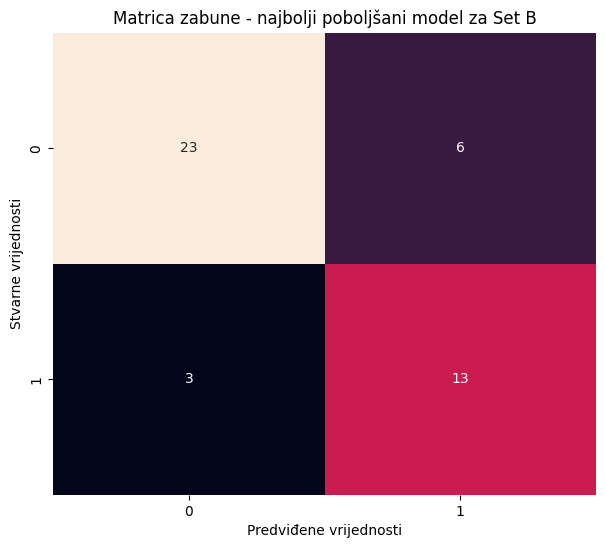

In [33]:
# Inicijalizacija parametara
dt_param_grid = {
    'max_depth': [3, 5, 10, None],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4],
    'class_weight': ['balanced', None]
}

# Inicijalizacija modela
dt_classifier = DecisionTreeClassifier()

# Izvođenje Grid Searcha 
grid_search_dt = GridSearchCV(estimator=dt_classifier, param_grid=dt_param_grid, 
                              cv=5, scoring='f1', verbose=1, n_jobs=-1)
grid_search_dt.fit(X_train2, y_train2)

# Najbolji parametri
print(f"Najbolji parametri za Decision Tree: {grid_search_dt.best_params_}")
print(f"Najbolji rezultat unakrsne validacije: {grid_search_dt.best_score_}")

# Evaluacija najboljeg modela 
best_dt = grid_search_dt.best_estimator_
y_pred_best_dt = best_dt.predict(X_test2)

# Ispis klasifikacijskog izvještaja
print(f"\nPoboljšan Decision Tree - SET B:\n{classification_report(y_test2, y_pred_best_dt)}")

# Izračun matrice zabune 
cm_dtc2 = confusion_matrix(y_test2, y_pred_best_dt)

# Plot matrice zabune za najbolji poboljšani model za Set B
plt.figure(figsize=(7, 6))
sns.heatmap(cm_dtc2, annot=True, fmt='d', cbar=False)
plt.title('Matrica zabune - najbolji poboljšani model za Set B')
plt.xlabel('Predviđene vrijednosti')
plt.ylabel('Stvarne vrijednosti')
plt.show()

Iz slike koja prikazuje matricu zabune zaključujemo da sad imamo bolji model. Također se i točnost povećala.

### Naive Bayes

Naive Bayes - SET A

               precision    recall  f1-score   support

           0       0.95      0.69      0.80        29
           1       0.17      0.75      0.27         4
           2       0.20      0.20      0.20         5
           3       0.00      0.00      0.00         6
           4       0.00      0.00      0.00         1

    accuracy                           0.53        45
   macro avg       0.26      0.33      0.25        45
weighted avg       0.65      0.53      0.56        45



Naive Bayes - SET B

               precision    recall  f1-score   support

           0       0.89      0.86      0.88        29
           1       0.76      0.81      0.79        16

    accuracy                           0.84        45
   macro avg       0.83      0.84      0.83        45
weighted avg       0.85      0.84      0.85        45





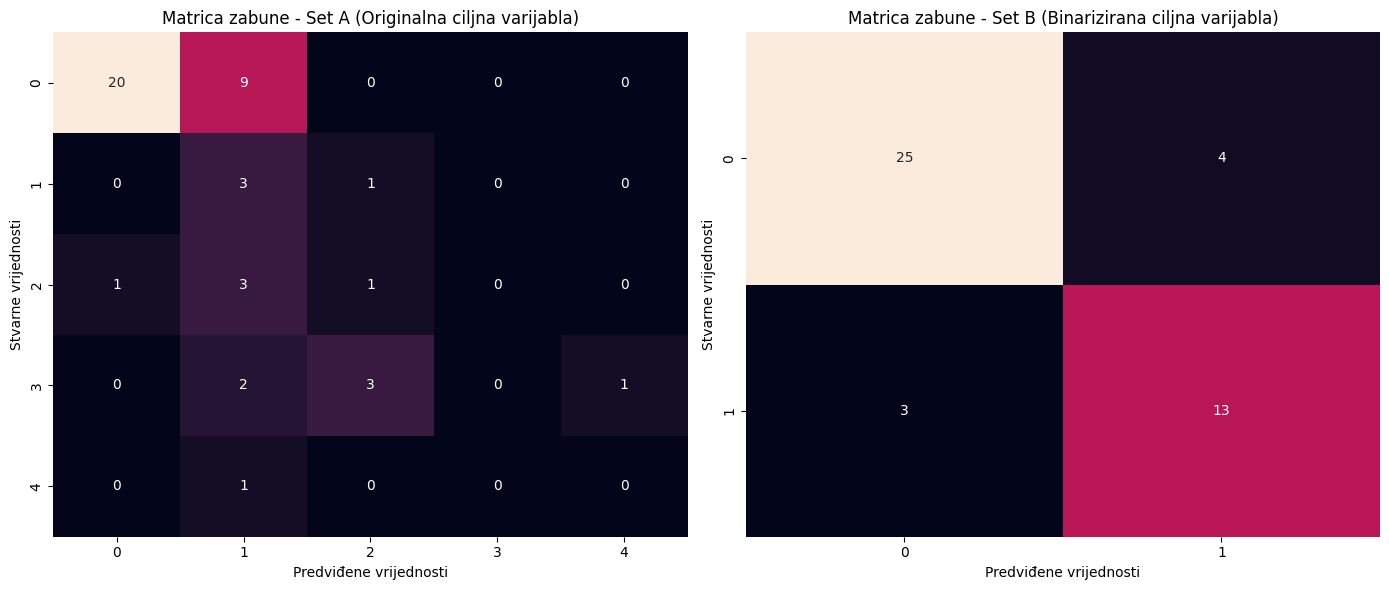

In [34]:
from sklearn.naive_bayes import GaussianNB
# Inicijalizacija modela
model_nb = GaussianNB()

# Model treniran na originalnim podacima (set A)
model_nb.fit(X_train1, y_train1)
y_pred_nb1 = model_nb.predict(X_test1)
report_nb1 = classification_report(y_test1, y_pred_nb1)

# Model treniran na binarnim podacima (set B)
model_nb.fit(X_train2, y_train2)
y_pred_nb2 = model_nb.predict(X_test2)
report_nb2 = classification_report(y_test2, y_pred_nb2)

# Ispis izvještaja
print(f"Naive Bayes - SET A\n\n {report_nb1}\n\n")
print(f"Naive Bayes - SET B\n\n {report_nb2}\n\n")

# Matrice zabune za oba seta
cm_nb1 = confusion_matrix(y_test1, y_pred_nb1)
cm_nb2 = confusion_matrix(y_test2, y_pred_nb2)

# Postavka za subplots (dva reda)
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Plot matrice zabune za set A
sns.heatmap(cm_nb1, annot=True, fmt='d', cbar=False, ax=axes[0])
axes[0].set_title('Matrica zabune - Set A (Originalna ciljna varijabla)')
axes[0].set_xlabel('Predviđene vrijednosti')
axes[0].set_ylabel('Stvarne vrijednosti')

# Plot matrice zabune za set B
sns.heatmap(cm_nb2, annot=True, fmt='d', cbar=False, ax=axes[1])
axes[1].set_title('Matrica zabune - Set B (Binarizirana ciljna varijabla)')
axes[1].set_xlabel('Predviđene vrijednosti')
axes[1].set_ylabel('Stvarne vrijednosti')

plt.tight_layout()
plt.show()


Rezultati pokazuju da model na Setu B (binarna ciljana varijabla) postiže mnogo bolje rezultate u odnosu na Set A (originalna ciljana varijabla). Set B ima visoku točnost (82,22%) i bolje performanse u pogledu preciznosti, odziva i F1-skorova za obje klase, dok Set A pokazuje nisku točnost (51,11%) zbog loših rezultata u manjinskim klasama (2, 3, 4). Korištenje binarne ciljne varijable pojednostavljuje problem, čineći ga lakšim za model da nauči i pravilno klasificira podatke.

### Random forest

In [35]:
from sklearn.ensemble import RandomForestClassifier

# Model treniran na originalnim podacima (set A) 
rf1 = RandomForestClassifier(class_weight='balanced')
rf1.fit(X_train1, y_train1)
y_pred1 = rf1.predict(X_test1)

# Model treniran na binarnim podacima (set B)
rf2 = RandomForestClassifier(class_weight='balanced')
rf2.fit(X_train2, y_train2)
y_pred2 = rf2.predict(X_test2)

# Ispis točnosti
print(f"Accuracy za SET A: {accuracy_score(y_test1, y_pred1)}")
print(f"Accuracy za SET B: {accuracy_score(y_test2, y_pred2)}")

Accuracy za SET A: 0.6222222222222222
Accuracy za SET B: 0.8666666666666667


Random Forest - SET A

               precision    recall  f1-score   support

           0       0.84      0.93      0.89        29
           1       0.10      0.25      0.14         4
           2       0.00      0.00      0.00         5
           3       0.00      0.00      0.00         6
           4       0.00      0.00      0.00         1

    accuracy                           0.62        45
   macro avg       0.19      0.24      0.21        45
weighted avg       0.55      0.62      0.58        45



Random Forest - SET B

               precision    recall  f1-score   support

           0       0.93      0.86      0.89        29
           1       0.78      0.88      0.82        16

    accuracy                           0.87        45
   macro avg       0.85      0.87      0.86        45
weighted avg       0.87      0.87      0.87        45





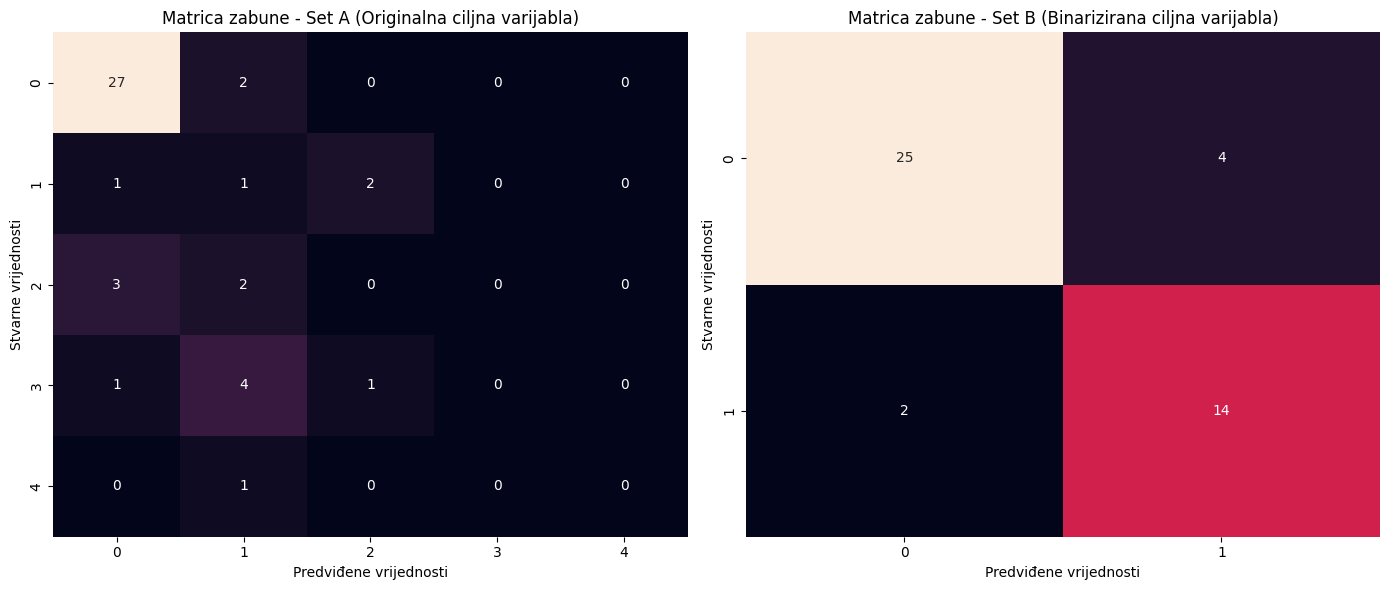

In [36]:
# Ispis izvještaja
print(f"Random Forest - SET A\n\n {classification_report(y_test1, y_pred1)}\n\n")
print(f"Random Forest - SET B\n\n {classification_report(y_test2, y_pred2)}\n\n")

# Matrice zabune za oba seta
cm_rf1 = confusion_matrix(y_test1, y_pred1)
cm_rf2 = confusion_matrix(y_test2, y_pred2)

# Postavka za subplots (dva reda)
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Plot matrice zabune za Set A
sns.heatmap(cm_rf1, annot=True, fmt='d', cbar=False, ax=axes[0])
axes[0].set_title('Matrica zabune - Set A (Originalna ciljna varijabla)')
axes[0].set_xlabel('Predviđene vrijednosti')
axes[0].set_ylabel('Stvarne vrijednosti')

# Plot matrice zabune za Set B
sns.heatmap(cm_rf2, annot=True, fmt='d', cbar=False, ax=axes[1])
axes[1].set_title('Matrica zabune - Set B (Binarizirana ciljna varijabla)')
axes[1].set_xlabel('Predviđene vrijednosti')
axes[1].set_ylabel('Stvarne vrijednosti')

plt.tight_layout()
plt.show()

Na setu podataka A imamo nešto bolji početni model od početnog modela s Decision Tree ako gledamo matricu zabune (možda zato što smo odmah primijenili class_weight='balanced'). Točnosti modela su veće i za A i za B set.

Opet ćemo pokušati poboljšati model na setu B mijenjajući hiperparametre. Za Random Forest pratit ćemo još i n_estimators tj. number of decision trees.

##### Poboljšanje modela na setu B

Fitting 5 folds for each of 108 candidates, totalling 540 fits
Najbolji parametri za Random Forest: {'max_depth': 3, 'min_samples_leaf': 2, 'min_samples_split': 2, 'n_estimators': 200}
Najbolji rezultat unakrsne validacije: 0.8209411764705882


Poboljšan Random Forest - Set B:
              precision    recall  f1-score   support

           0       0.93      0.93      0.93        29
           1       0.88      0.88      0.88        16

    accuracy                           0.91        45
   macro avg       0.90      0.90      0.90        45
weighted avg       0.91      0.91      0.91        45



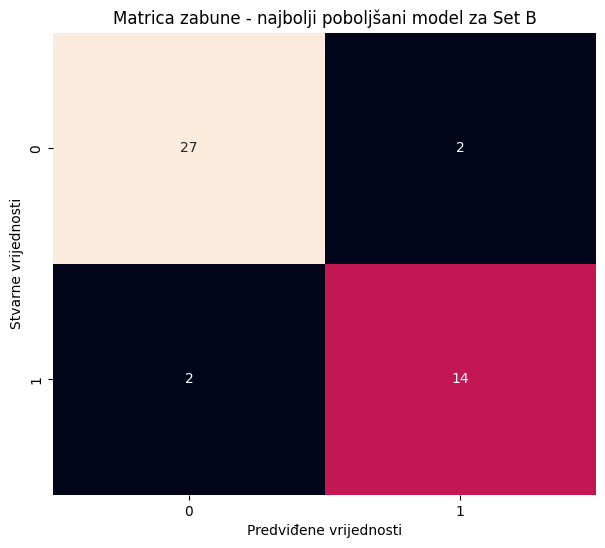

In [37]:
# Inicijalizacija parametara
rf_param_grid = {
    'n_estimators': [50, 100, 200],
    'max_depth': [3, 5, 10, None],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4]
}

# Inicijalizacija modela
rf_classifier = RandomForestClassifier()

# Izvođenje Grid Searcha
grid_search_rf = GridSearchCV(estimator=rf_classifier, param_grid=rf_param_grid, 
                              cv=5, scoring='accuracy', verbose=1, n_jobs=-1)
grid_search_rf.fit(X_train2, y_train2)

# Najbolji parametri
print(f"Najbolji parametri za Random Forest: {grid_search_rf.best_params_}")
print(f"Najbolji rezultat unakrsne validacije: {grid_search_rf.best_score_}")

# Evaluacija najboljeg modela
best_rf = grid_search_rf.best_estimator_
y_pred_best_rf = best_rf.predict(X_test2)

# Ispis klasifikacijskog izvještaja
print(f"\n\nPoboljšan Random Forest - Set B:\n{classification_report(y_test2, y_pred_best_rf)}")

# Izračun matrice zabune
cm_rf2 = confusion_matrix(y_test2, y_pred_best_rf)

# Plot matrice zabune za najbolji poboljšani model za Set B
plt.figure(figsize=(7, 6))
sns.heatmap(cm_rf2, annot=True, fmt='d', cbar=False)
plt.title('Matrica zabune - najbolji poboljšani model za Set B')
plt.xlabel('Predviđene vrijednosti')
plt.ylabel('Stvarne vrijednosti')
plt.show()


Vidimo da smo dobili bolji model koristeći optimizirani Random Forest od Decision Treea što smo i očekivali.

Još ćemo pogledati kako se F1 score ponaša kad mijenjamo n_estimators.

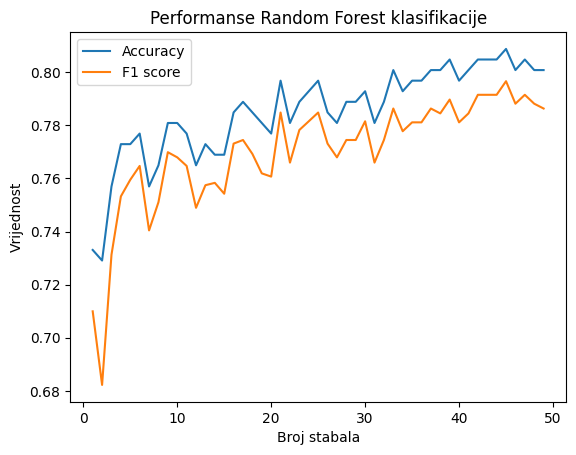

In [38]:
# Inicijalizacija raspona za broj stabala (n_estimators)
number_trees = [n for n in range(1, 50)]

# Inicijalizacija listi za rezultate performansi
accuracy_scores = []
f1_scores = []

# Evaluacija performansi kroz petlju
for nt in number_trees:
    clf = RandomForestClassifier(max_depth=5, 
                                 random_state=0, 
                                 n_estimators=nt, 
                                 class_weight='balanced')

    clf.fit(X_train2, y_train2)

    # Kreiranje predikcija unakrsnom validacijom
    y_pred = cross_val_predict(clf, X_train2, y_train2, cv=5)

    # Izračun accuracya i f1 scorea
    accuracy_scores.append(accuracy_score(y_train2, y_pred))
    f1_scores.append(f1_score(y_train2, y_pred))

# Plot performansi
plt.plot(number_trees, accuracy_scores, label="Accuracy")
plt.plot(number_trees, f1_scores, label="F1 score")
plt.title("Performanse Random Forest klasifikacije")
plt.ylabel("Vrijednost")
plt.xlabel("Broj stabala")
plt.legend()
plt.show()

### Logistic regression

Logistička regresija - SET A

               precision    recall  f1-score   support

           0       0.89      0.86      0.88        29
           1       0.12      0.25      0.17         4
           2       0.33      0.20      0.25         5
           3       0.50      0.50      0.50         6
           4       0.00      0.00      0.00         1

    accuracy                           0.67        45
   macro avg       0.37      0.36      0.36        45
weighted avg       0.69      0.67      0.67        45



Logistička regresija - SET B

               precision    recall  f1-score   support

           0       0.88      0.79      0.84        29
           1       0.68      0.81      0.74        16

    accuracy                           0.80        45
   macro avg       0.78      0.80      0.79        45
weighted avg       0.81      0.80      0.80        45





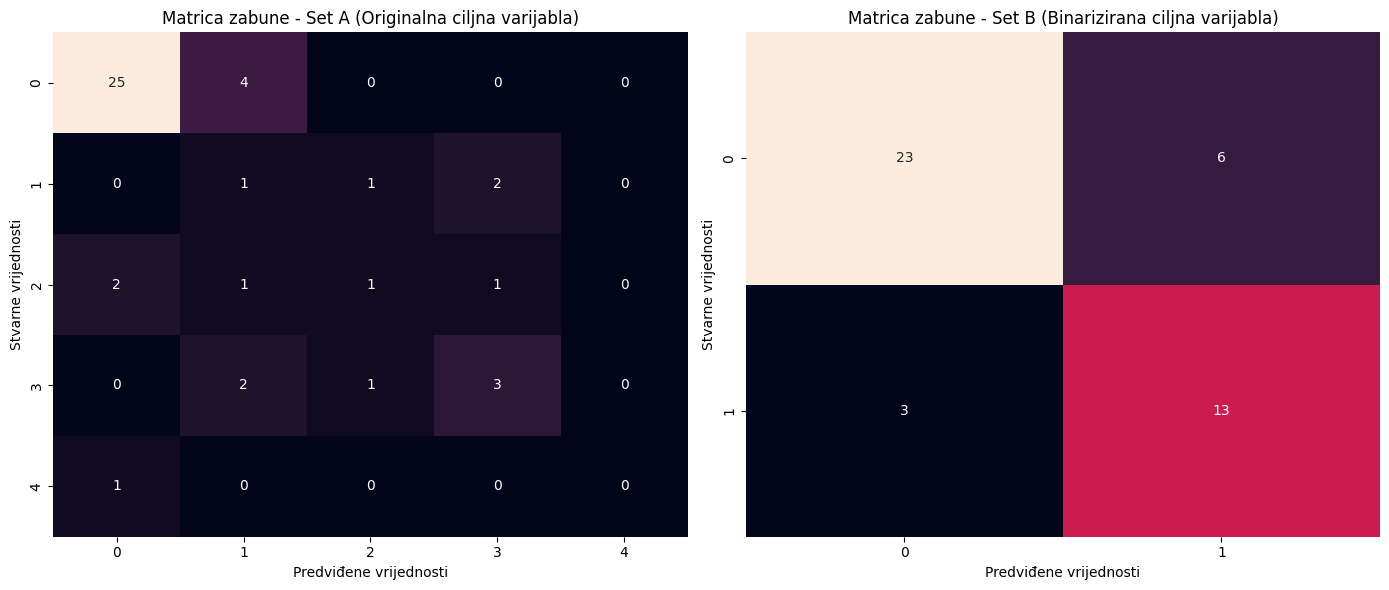

In [39]:
from sklearn.linear_model import LogisticRegression

# Inicijalizacija modela
model_lr1 = LogisticRegression()
model_lr2 = LogisticRegression()

# Model treniran na originalnim podacima (Set A)
model_lr1.fit(X_train3, y_train3)
y_pred1 = model_lr1.predict(X_test3)
report_lr1 = classification_report(y_test3, y_pred1)

# Model treniran na binarnim podacima (Set B)
model_lr2.fit(X_train4, y_train4)
y_pred2 = model_lr2.predict(X_test4)
report_lr2 = classification_report(y_test4, y_pred2)

# Ispis izvještaja
print(f"Logistička regresija - SET A\n\n {report_lr1}\n\n")
print(f"Logistička regresija - SET B\n\n {report_lr2}\n\n")

# Matrice zabune za oba seta
cm_lr1 = confusion_matrix(y_test3, y_pred1)
cm_lr2 = confusion_matrix(y_test4, y_pred2)

# Postavka za subplots (dva reda)
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Plot matrice zabune za Set A
sns.heatmap(cm_lr1, annot=True, fmt='d', cbar=False, ax=axes[0])
axes[0].set_title('Matrica zabune - Set A (Originalna ciljna varijabla)')
axes[0].set_xlabel('Predviđene vrijednosti')
axes[0].set_ylabel('Stvarne vrijednosti')

# Plot matrice zabune za Set B
sns.heatmap(cm_lr2, annot=True, fmt='d', cbar=False, ax=axes[1])
axes[1].set_title('Matrica zabune - Set B (Binarizirana ciljna varijabla)')
axes[1].set_xlabel('Predviđene vrijednosti')
axes[1].set_ylabel('Stvarne vrijednosti')

plt.tight_layout()
plt.show()


Iz podataka za set A (originalne ciljne varijable) vidimo da dobro funkcionira za ciljne varijable 0, lošije za ciljne varijable 1, 2 i 3, dok ne funkcionira za ciljnu varijablu 4. Iz podataka za set B (binarizirane ciljne varijable) vidimo da dobro funkcionira za obje ciljne varijable 0 i 1, te da općenito ostvaruje bolje performanse od seta A. 

Moguće je ostvariti efekt bolje generalizacije logističke regresije primjenom L2 regularizacije. To je metoda koja dodaje penalizaciju na vrijednosti koeficijenta modela čime smanjuje kompleksnost modela. Testiranjem parametra C pronalazimo optimalan model.

Logistička regresija s L2 regularizacijom (C=0.01) - SET A

               precision    recall  f1-score   support

           0       0.85      0.97      0.90        29
           1       0.40      0.50      0.44         4
           2       0.00      0.00      0.00         5
           3       0.67      0.67      0.67         6
           4       0.00      0.00      0.00         1

    accuracy                           0.76        45
   macro avg       0.38      0.43      0.40        45
weighted avg       0.67      0.76      0.71        45



Logistička regresija s L2 regularizacijom (C=0.1) - SET B

               precision    recall  f1-score   support

           0       0.88      0.79      0.84        29
           1       0.68      0.81      0.74        16

    accuracy                           0.80        45
   macro avg       0.78      0.80      0.79        45
weighted avg       0.81      0.80      0.80        45





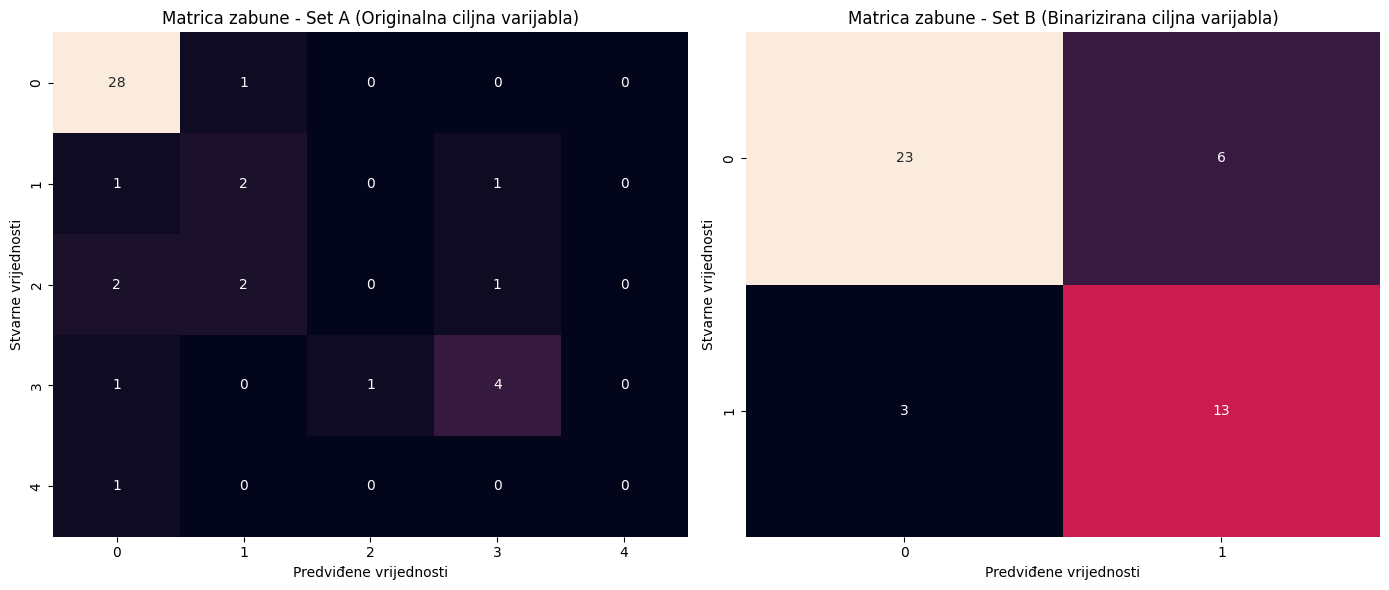

In [40]:
# Inicijalizacija modela s L2 regularizacijom
param_grid = {
    'C': [0.0001, 0.001, 0.01, 0.1, 1, 10, 100, 1000, 10000],
    'penalty': ['l2'],
    'solver': ['liblinear', 'saga']
}
model_1 = LogisticRegression()
model_2 = LogisticRegression()
grid_search_1 = GridSearchCV(estimator=model_1, param_grid=param_grid, cv=5, scoring='f1_weighted', n_jobs=-1)
grid_search_2 = GridSearchCV(estimator=model_2, param_grid=param_grid, cv=5, scoring='f1_weighted', n_jobs=-1)

# Model treniran na originalnim podacima (Set A)
grid_search_1.fit(X_train3, y_train3)
best_model_1 = grid_search_1.best_estimator_
y_pred_l2_1 = best_model_1.predict(X_test3)
report_l2_1 = classification_report(y_test3, y_pred_l2_1)

# Model treniran na binarnim podacima (Set B)
grid_search_2.fit(X_train4, y_train4)
best_model_2 = grid_search_2.best_estimator_
y_pred_l2_2 = best_model_2.predict(X_test4)
report_l2_2 = classification_report(y_test4, y_pred_l2_2)

# Ispis izvještaja
print(f"Logistička regresija s L2 regularizacijom (C={grid_search_1.best_params_['C']}) - SET A\n\n {report_l2_1}\n\n")
print(f"Logistička regresija s L2 regularizacijom (C={grid_search_2.best_params_['C']}) - SET B\n\n {report_l2_2}\n\n")

# Matrice zabune za oba seta
cm_l2_1 = confusion_matrix(y_test3, y_pred_l2_1)
cm_l2_2 = confusion_matrix(y_test4, y_pred_l2_2)

# Postavka za subplots (dva reda)
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Plot matrice zabune za Set A
sns.heatmap(cm_l2_1, annot=True, fmt='d', cbar=False, ax=axes[0])
axes[0].set_title('Matrica zabune - Set A (Originalna ciljna varijabla)')
axes[0].set_xlabel('Predviđene vrijednosti')
axes[0].set_ylabel('Stvarne vrijednosti')

# Plot matrice zabune za Set B
sns.heatmap(cm_l2_2, annot=True, fmt='d', cbar=False, ax=axes[1])
axes[1].set_title('Matrica zabune - Set B (Binarizirana ciljna varijabla)')
axes[1].set_xlabel('Predviđene vrijednosti')
axes[1].set_ylabel('Stvarne vrijednosti')

plt.tight_layout()
plt.show()


Korištenjem L2 regularizacije s parametrom C=0.1 u setu A dobivamo bolje rezultate. Korištenjem L2 regularizacije na set B nismo uspjeli dobiti bolje rezultate. 

### SVM

Postoje tri vrste stroja potpornih vektora (SVM) ovisno o jezgrenoj funkciji. Jezgrena funkcija može biti linearna, polinomijalna i radijalno bazna funkcija. U nastavku prikazati ćemo postupak za sve tri verzije stroja potpornih vektora.

##### Linearna jezgrena funkcija

SVM s linearnom jezgrenom funkcijom - SET A

               precision    recall  f1-score   support

           0       0.86      0.83      0.84        29
           1       0.11      0.25      0.15         4
           2       0.25      0.20      0.22         5
           3       0.50      0.33      0.40         6
           4       0.00      0.00      0.00         1

    accuracy                           0.62        45
   macro avg       0.34      0.32      0.32        45
weighted avg       0.66      0.62      0.63        45



SVM s linearnom jezgrenom funkcijom - SET B

               precision    recall  f1-score   support

           0       0.88      0.79      0.84        29
           1       0.68      0.81      0.74        16

    accuracy                           0.80        45
   macro avg       0.78      0.80      0.79        45
weighted avg       0.81      0.80      0.80        45





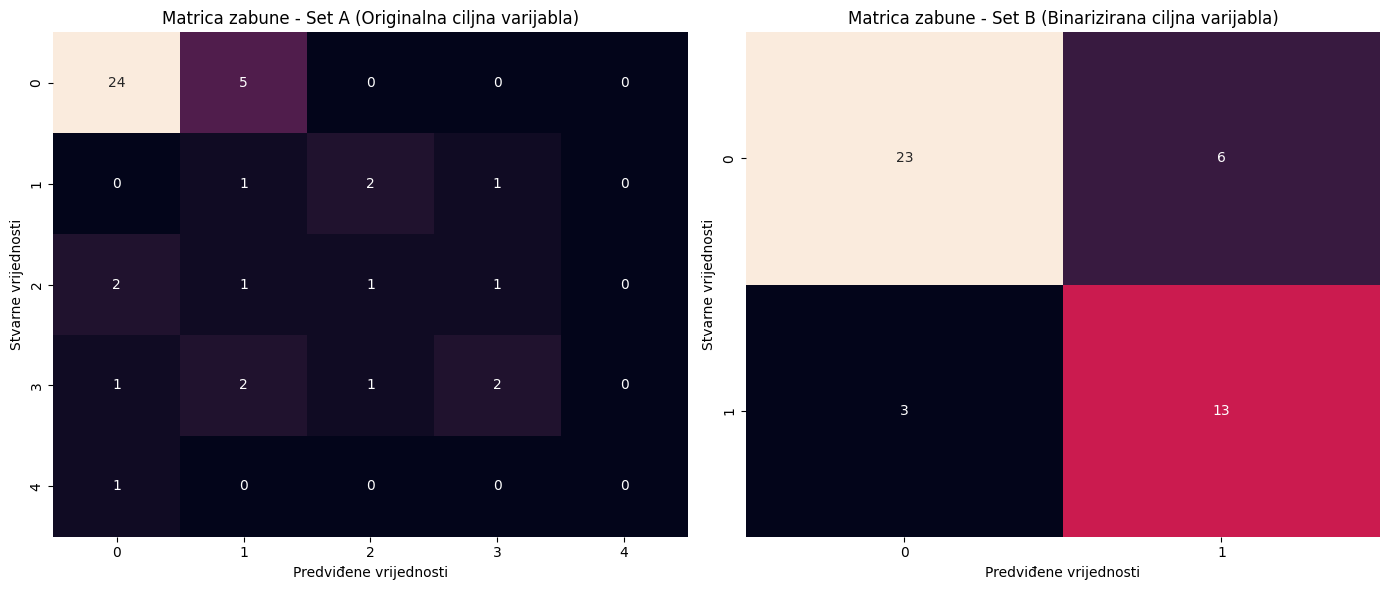

In [41]:
from sklearn.svm import SVC

# Inicijalizacija modela sa linearnom jezgrenom funkcijom
model_linear_1 = SVC(kernel='linear')
model_linear_2 = SVC(kernel='linear')

# Model treniran na originalnim podacima (Set A)
model_linear_1.fit(X_train3, y_train3)
y_pred_linear_1 = model_linear_1.predict(X_test3)
report_linear_1 = classification_report(y_test3, y_pred_linear_1)

# Model treniran na binarnim podacima (Set B)
model_linear_2.fit(X_train4, y_train4)
y_pred_linear_2 = model_linear_2.predict(X_test4)
report_linear_2 = classification_report(y_test4, y_pred_linear_2)
# Ispis izvještaja
print(f"SVM s linearnom jezgrenom funkcijom - SET A\n\n {report_linear_1}\n\n")
print(f"SVM s linearnom jezgrenom funkcijom - SET B\n\n {report_linear_2}\n\n")

# Matrice zabune za oba seta
cm_linear_1 = confusion_matrix(y_test3, y_pred_linear_1)
cm_linear_2 = confusion_matrix(y_test4, y_pred_linear_2)

# Postavka za subplots (dva reda)
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Plot matrice zabune za Set A
sns.heatmap(cm_linear_1, annot=True, fmt='d', cbar=False, ax=axes[0])
axes[0].set_title('Matrica zabune - Set A (Originalna ciljna varijabla)')
axes[0].set_xlabel('Predviđene vrijednosti')
axes[0].set_ylabel('Stvarne vrijednosti')

# Plot matrice zabune za Set B
sns.heatmap(cm_linear_2, annot=True, fmt='d', cbar=False, ax=axes[1])
axes[1].set_title('Matrica zabune - Set B (Binarizirana ciljna varijabla)')
axes[1].set_xlabel('Predviđene vrijednosti')
axes[1].set_ylabel('Stvarne vrijednosti')

plt.tight_layout()
plt.show()

Iz podataka za set A (originalne ciljne varijable) vidimo da dobro funkcionira za ciljne varijable 0, lošije za ciljne varijable 1, 2 i 3, dok ne funkcionira za ciljnu varijablu 4. Iz podataka za set B (binarizirane ciljne varijable) vidimo da dobro funkcionira za obje ciljne varijable 0 i 1, te da općenito ostvaruje bolje performanse od seta A. 

Moguće je odabrati različite vrijednosti regularizacijskog faktora C.

SVM s linearnom jezgrenom funkcijom (C=0.1) - SET A

               precision    recall  f1-score   support

           0       0.84      0.90      0.87        29
           1       0.12      0.25      0.17         4
           2       0.25      0.20      0.22         5
           3       0.50      0.17      0.25         6
           4       0.00      0.00      0.00         1

    accuracy                           0.64        45
   macro avg       0.34      0.30      0.30        45
weighted avg       0.65      0.64      0.63        45



SVM s linearnom jezgrenom funkcijom (C=0.1) - SET B

               precision    recall  f1-score   support

           0       0.92      0.79      0.85        29
           1       0.70      0.88      0.78        16

    accuracy                           0.82        45
   macro avg       0.81      0.83      0.81        45
weighted avg       0.84      0.82      0.83        45





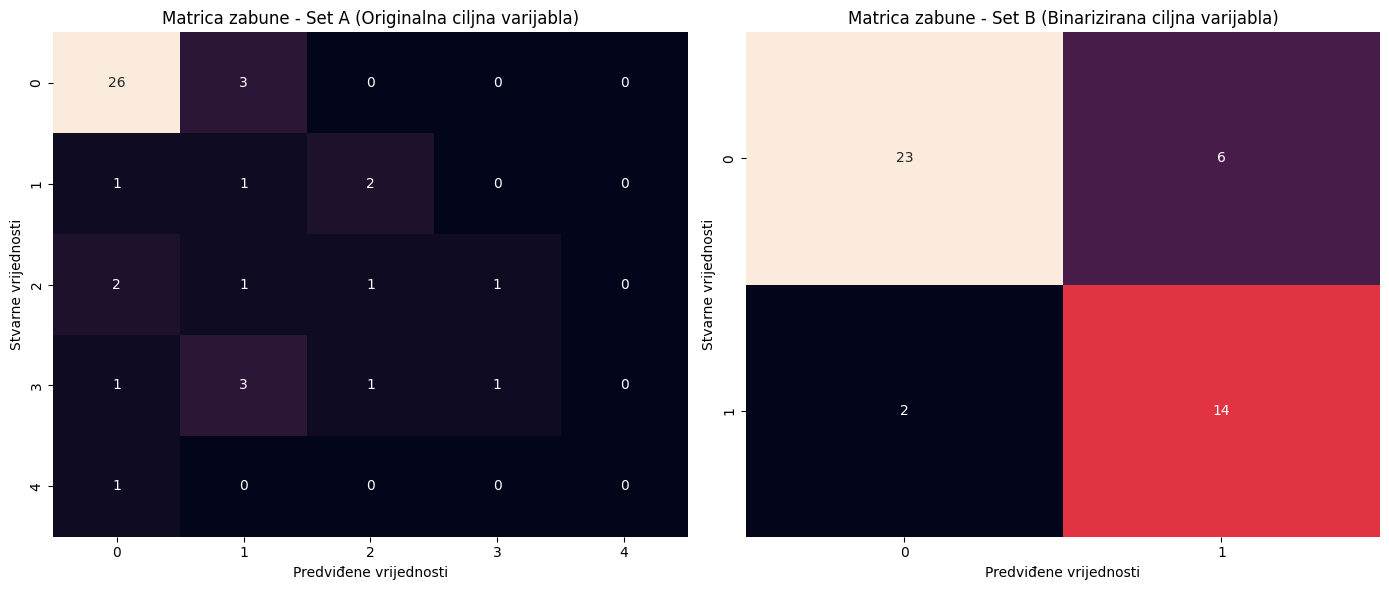

In [42]:
# Inicijalizacija modela sa linearnom jezgrenom funkcijom
param_grid = {
    'C': [0.01, 0.1, 1, 10, 100]
}
model_linear_1 = SVC(kernel='linear')
model_linear_2 = SVC(kernel='linear')
grid_search_1 = GridSearchCV(estimator=model_linear_1, param_grid=param_grid, cv=5, scoring='f1_weighted', n_jobs=-1)
grid_search_2 = GridSearchCV(estimator=model_linear_2, param_grid=param_grid, cv=5, scoring='f1_weighted', n_jobs=-1)

# Treniranje modela na podacima (set A)
grid_search_1.fit(X_train3, y_train3)
best_model_1 = grid_search_1.best_estimator_
y_pred_linear_01_1 = best_model_1.predict(X_test3)
report_linear_01_1 = classification_report(y_test3, y_pred_linear_01_1)

# Treniranje modela na binarnim podacima (set B)
grid_search_2.fit(X_train4, y_train4)
best_model_2 = grid_search_2.best_estimator_
y_pred_linear_01_2 = best_model_2.predict(X_test4)
report_linear_01_2 = classification_report(y_test4, y_pred_linear_01_2)

# Ispis izvještaja
print(f"SVM s linearnom jezgrenom funkcijom (C={grid_search_1.best_params_['C']}) - SET A\n\n {report_linear_01_1}\n\n")
print(f"SVM s linearnom jezgrenom funkcijom (C={grid_search_2.best_params_['C']}) - SET B\n\n {report_linear_01_2}\n\n")

# Matrice zabune za oba seta
cm_linear_01_1 = confusion_matrix(y_test3, y_pred_linear_01_1)
cm_linear_01_2 = confusion_matrix(y_test4, y_pred_linear_01_2)

# Postavka za subplots (dva reda)
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Plot matrice zabune za Set A
sns.heatmap(cm_linear_01_1, annot=True, fmt='d', cbar=False, ax=axes[0])
axes[0].set_title('Matrica zabune - Set A (Originalna ciljna varijabla)')
axes[0].set_xlabel('Predviđene vrijednosti')
axes[0].set_ylabel('Stvarne vrijednosti')

# Plot matrice zabune za Set B
sns.heatmap(cm_linear_01_2, annot=True, fmt='d', cbar=False, ax=axes[1])
axes[1].set_title('Matrica zabune - Set B (Binarizirana ciljna varijabla)')
axes[1].set_xlabel('Predviđene vrijednosti')
axes[1].set_ylabel('Stvarne vrijednosti')

plt.tight_layout()
plt.show()


Korištenjem L2 regularizacije na setu A dobivamo losije rezultate. Korištenjem L2 regularizacije s parametrom C=0.1 na set B dobivamo bolje rezultate. 

##### Polinomijalna jezgrena funkcija

SVM s polinomijalnom jezgrenom funkcijom - SET A

               precision    recall  f1-score   support

           0       0.76      0.97      0.85        29
           1       0.00      0.00      0.00         4
           2       0.00      0.00      0.00         5
           3       1.00      0.17      0.29         6
           4       0.00      0.00      0.00         1

    accuracy                           0.64        45
   macro avg       0.35      0.23      0.23        45
weighted avg       0.62      0.64      0.58        45



SVM s polinomijalnom jezgrenom funkcijom - SET B

               precision    recall  f1-score   support

           0       0.89      0.86      0.88        29
           1       0.76      0.81      0.79        16

    accuracy                           0.84        45
   macro avg       0.83      0.84      0.83        45
weighted avg       0.85      0.84      0.85        45





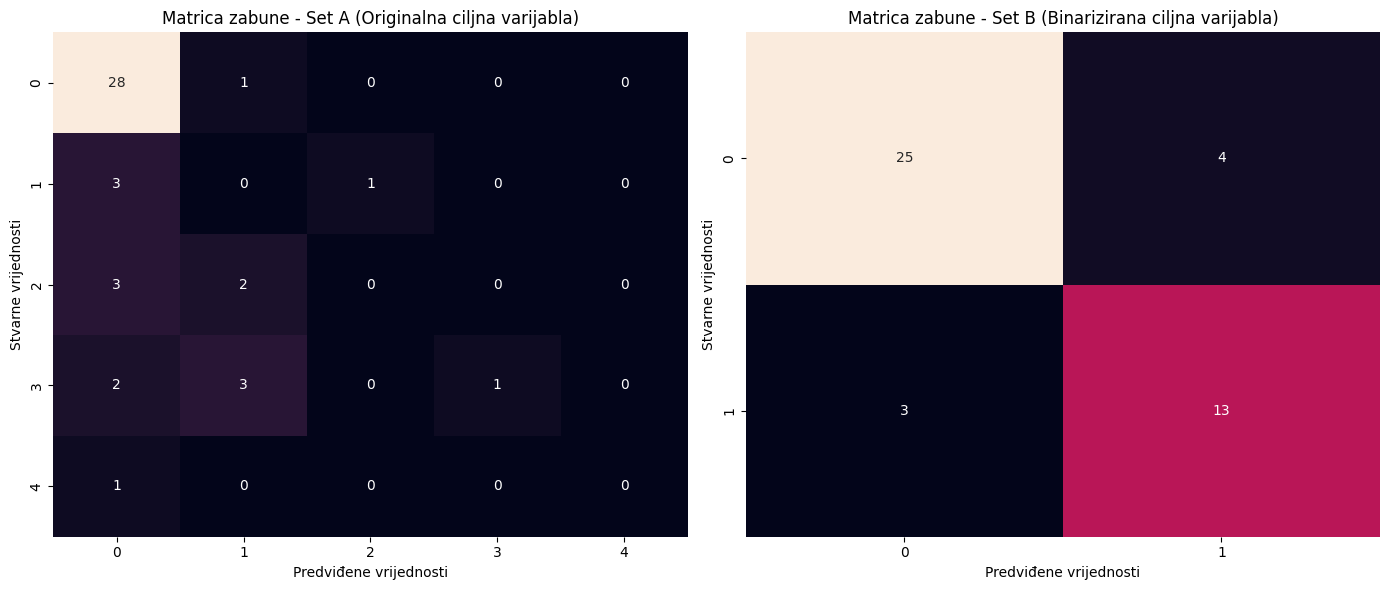

In [43]:
# Inicijalizacija modela s polinomijalnom jezgrenom funkcijom
model_poly_1 = SVC(kernel='poly')
model_poly_2 = SVC(kernel='poly')

# Treniranje modela na originalnim podacima (set A)
model_poly_1.fit(X_train3, y_train3)
y_pred_poly_1 = model_poly_1.predict(X_test3)
report_poly_1 = classification_report(y_test3, y_pred_poly_1)

# Treniranje modela na binarnim podacima (set B)
model_poly_2.fit(X_train4, y_train4)
y_pred_poly_2 = model_poly_2.predict(X_test4)
report_poly_2 = classification_report(y_test4, y_pred_poly_2)

# Ispis izvještaja
print(f"SVM s polinomijalnom jezgrenom funkcijom - SET A\n\n {report_poly_1}\n\n")
print(f"SVM s polinomijalnom jezgrenom funkcijom - SET B\n\n {report_poly_2}\n\n")

# Matrice zabune za oba seta
cm_poly_1 = confusion_matrix(y_test3, y_pred_poly_1)
cm_poly_2 = confusion_matrix(y_test4, y_pred_poly_2)

# Postavka za subplots (dva reda)
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Plot matrice zabune za Set A
sns.heatmap(cm_poly_1, annot=True, fmt='d', cbar=False, ax=axes[0])
axes[0].set_title('Matrica zabune - Set A (Originalna ciljna varijabla)')
axes[0].set_xlabel('Predviđene vrijednosti')
axes[0].set_ylabel('Stvarne vrijednosti')

# Plot matrice zabune za Set B
sns.heatmap(cm_poly_2, annot=True, fmt='d', cbar=False, ax=axes[1])
axes[1].set_title('Matrica zabune - Set B (Binarizirana ciljna varijabla)')
axes[1].set_xlabel('Predviđene vrijednosti')
axes[1].set_ylabel('Stvarne vrijednosti')

plt.tight_layout()
plt.show()


Iz podataka za set A (originalne ciljne varijable) vidimo da dobro funkcionira za ciljne varijable 0, lošije za ciljne varijable 3, dok ne funkcionira za ciljnu varijablu 1, 2 i 4. Iz podataka za set B (binarizirane ciljne varijable) vidimo da dobro funkcionira za obje ciljne varijable 0 i 1, te da općenito ostvaruje bolje performanse od seta A. 

SVM s polinomijalnom jezgrenom funkcijom (C=10) - SET A

               precision    recall  f1-score   support

           0       0.88      0.76      0.81        29
           1       0.00      0.00      0.00         4
           2       0.25      0.20      0.22         5
           3       1.00      0.17      0.29         6
           4       0.00      0.00      0.00         1

    accuracy                           0.53        45
   macro avg       0.43      0.23      0.26        45
weighted avg       0.73      0.53      0.59        45



SVM s polinomijalnom jezgrenom funkcijom (C=1) - SET B

               precision    recall  f1-score   support

           0       0.89      0.86      0.88        29
           1       0.76      0.81      0.79        16

    accuracy                           0.84        45
   macro avg       0.83      0.84      0.83        45
weighted avg       0.85      0.84      0.85        45





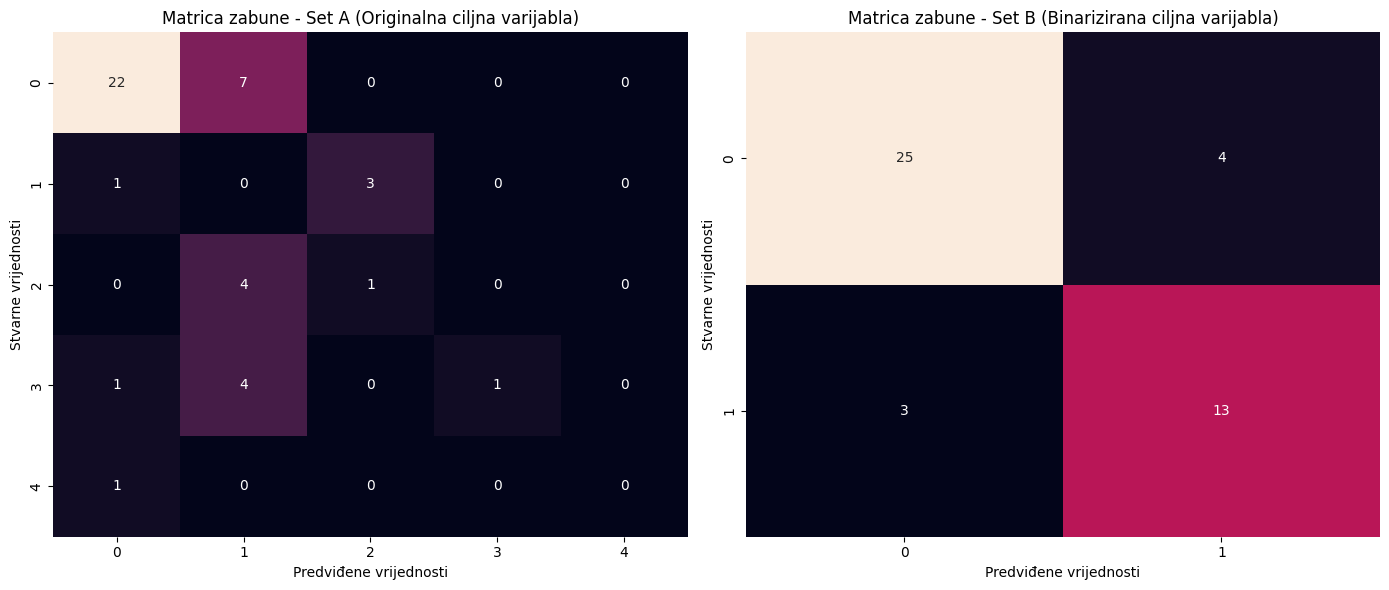

In [44]:
# Inicijalizacija modela s polinomijalnom jezgrenom funkcijom
param_grid = {
    'C': [0.01, 0.1, 1, 10, 100]
}
model_poly_1 = SVC(kernel='poly')
model_poly_2 = SVC(kernel='poly')
grid_search_1 = GridSearchCV(estimator=model_poly_1, param_grid=param_grid, cv=5, scoring='f1_weighted', n_jobs=-1)
grid_search_2 = GridSearchCV(estimator=model_poly_2, param_grid=param_grid, cv=5, scoring='f1_weighted', n_jobs=-1)

# Treniranje modela na originalnim podacima (set A)
grid_search_1.fit(X_train3, y_train3)
best_model_1 = grid_search_1.best_estimator_
y_pred_poly_1 = best_model_1.predict(X_test3)
report_poly_1 = classification_report(y_test3, y_pred_poly_1)

# Treniranje modela na binarnim podacima (set B)
grid_search_2.fit(X_train4, y_train4)
best_model_2 = grid_search_2.best_estimator_
y_pred_poly_2 = best_model_2.predict(X_test4)
report_poly_2 = classification_report(y_test4, y_pred_poly_2)

# Ispis izvještaja
print(f"SVM s polinomijalnom jezgrenom funkcijom (C={grid_search_1.best_params_['C']}) - SET A\n\n {report_poly_1}\n\n")
print(f"SVM s polinomijalnom jezgrenom funkcijom (C={grid_search_2.best_params_['C']}) - SET B\n\n {report_poly_2}\n\n")

# Matrice zabune za oba seta
cm_poly_1 = confusion_matrix(y_test3, y_pred_poly_1)
cm_poly_2 = confusion_matrix(y_test4, y_pred_poly_2)

# Postavka za subplots (dva reda)
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Plot matrice zabune za Set A
sns.heatmap(cm_poly_1, annot=True, fmt='d', cbar=False, ax=axes[0])
axes[0].set_title('Matrica zabune - Set A (Originalna ciljna varijabla)')
axes[0].set_xlabel('Predviđene vrijednosti')
axes[0].set_ylabel('Stvarne vrijednosti')

# Plot matrice zabune za Set B
sns.heatmap(cm_poly_2, annot=True, fmt='d', cbar=False, ax=axes[1])
axes[1].set_title('Matrica zabune - Set B (Binarizirana ciljna varijabla)')
axes[1].set_xlabel('Predviđene vrijednosti')
axes[1].set_ylabel('Stvarne vrijednosti')

plt.tight_layout()
plt.show()

Korištenjem L2 regularizacije s parametrom C=10 na setu A dobivamo bolje rezultate. Korištenjem L2 regularizacije na setu B dobivamo jednake rezultate. 

##### Radijalna bazna jezgrena funkcija

SVM s radijalnom baznom jezgrenom funkcijom - SET A

               precision    recall  f1-score   support

           0       0.84      0.93      0.89        29
           1       0.00      0.00      0.00         4
           2       0.00      0.00      0.00         5
           3       0.50      0.17      0.25         6
           4       0.00      0.00      0.00         1

    accuracy                           0.62        45
   macro avg       0.27      0.22      0.23        45
weighted avg       0.61      0.62      0.60        45



SVM s radijalnom baznom jezgrenom funkcijom - SET B

               precision    recall  f1-score   support

           0       0.96      0.79      0.87        29
           1       0.71      0.94      0.81        16

    accuracy                           0.84        45
   macro avg       0.84      0.87      0.84        45
weighted avg       0.87      0.84      0.85        45





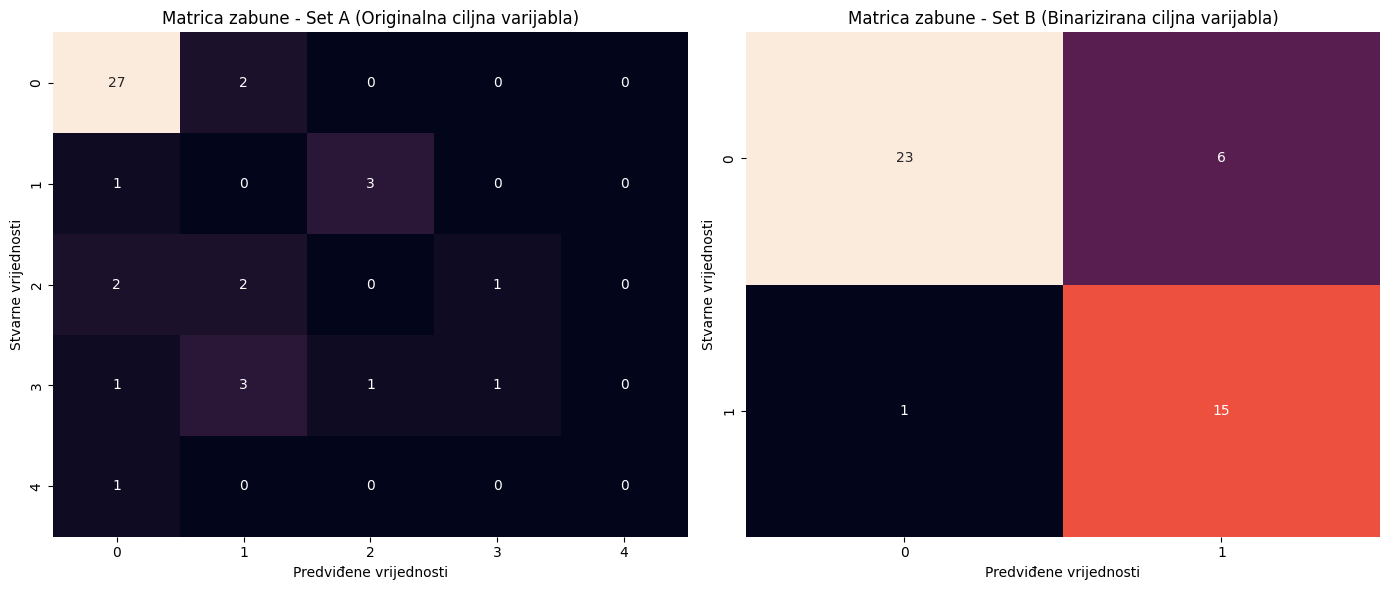

In [45]:
# Inicijalizacija modela s radijalnom baznom jezgrenom funkcijom
model_rbf_1 = SVC(kernel='rbf')
model_rbf_2 = SVC(kernel='rbf')

# Treniranje modela na originalnim podacima (set A)
model_rbf_1.fit(X_train3, y_train3)
y_pred_rbf_1 = model_rbf_1.predict(X_test3)
report_rbf_1 = classification_report(y_test3, y_pred_rbf_1)

# Treniranje modela na binarnim podacima (set B)
model_rbf_2.fit(X_train4, y_train4)
y_pred_rbf_2 = model_rbf_2.predict(X_test4)
report_rbf_2 = classification_report(y_test4, y_pred_rbf_2)

# Ispis izvještaja
print(f"SVM s radijalnom baznom jezgrenom funkcijom - SET A\n\n {report_rbf_1}\n\n")
print(f"SVM s radijalnom baznom jezgrenom funkcijom - SET B\n\n {report_rbf_2}\n\n")

# Matrice zabune za oba seta
cm_rbf_1 = confusion_matrix(y_test3, y_pred_rbf_1)
cm_rbf_2 = confusion_matrix(y_test4, y_pred_rbf_2)

# Postavka za subplots (dva reda)
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Plot matrice zabune za Set A
sns.heatmap(cm_rbf_1, annot=True, fmt='d', cbar=False, ax=axes[0])
axes[0].set_title('Matrica zabune - Set A (Originalna ciljna varijabla)')
axes[0].set_xlabel('Predviđene vrijednosti')
axes[0].set_ylabel('Stvarne vrijednosti')

# Plot matrice zabune za Set B
sns.heatmap(cm_rbf_2, annot=True, fmt='d', cbar=False, ax=axes[1])
axes[1].set_title('Matrica zabune - Set B (Binarizirana ciljna varijabla)')
axes[1].set_xlabel('Predviđene vrijednosti')
axes[1].set_ylabel('Stvarne vrijednosti')

plt.tight_layout()
plt.show()


Iz podataka za set A (originalne ciljne varijable) vidimo da dobro funkcionira za ciljne varijable 0, lošije za ciljne varijable 3, dok ne funkcionira za ciljnu varijablu 1, 2 i 4. Iz podataka za set B (binarizirane ciljne varijable) vidimo da dobro funkcionira za obje ciljne varijable 0 i 1, te da općenito ostvaruje bolje performanse od seta A. 

SVM s radijalnom baznom jezgrenom funkcijom (C=10) - SET A

               precision    recall  f1-score   support

           0       0.92      0.76      0.83        29
           1       0.00      0.00      0.00         4
           2       0.00      0.00      0.00         5
           3       0.33      0.17      0.22         6
           4       0.00      0.00      0.00         1

    accuracy                           0.51        45
   macro avg       0.25      0.19      0.21        45
weighted avg       0.64      0.51      0.56        45



SVM s radijalnom baznom jezgrenom funkcijom (C=0.1) - SET B

               precision    recall  f1-score   support

           0       0.96      0.79      0.87        29
           1       0.71      0.94      0.81        16

    accuracy                           0.84        45
   macro avg       0.84      0.87      0.84        45
weighted avg       0.87      0.84      0.85        45





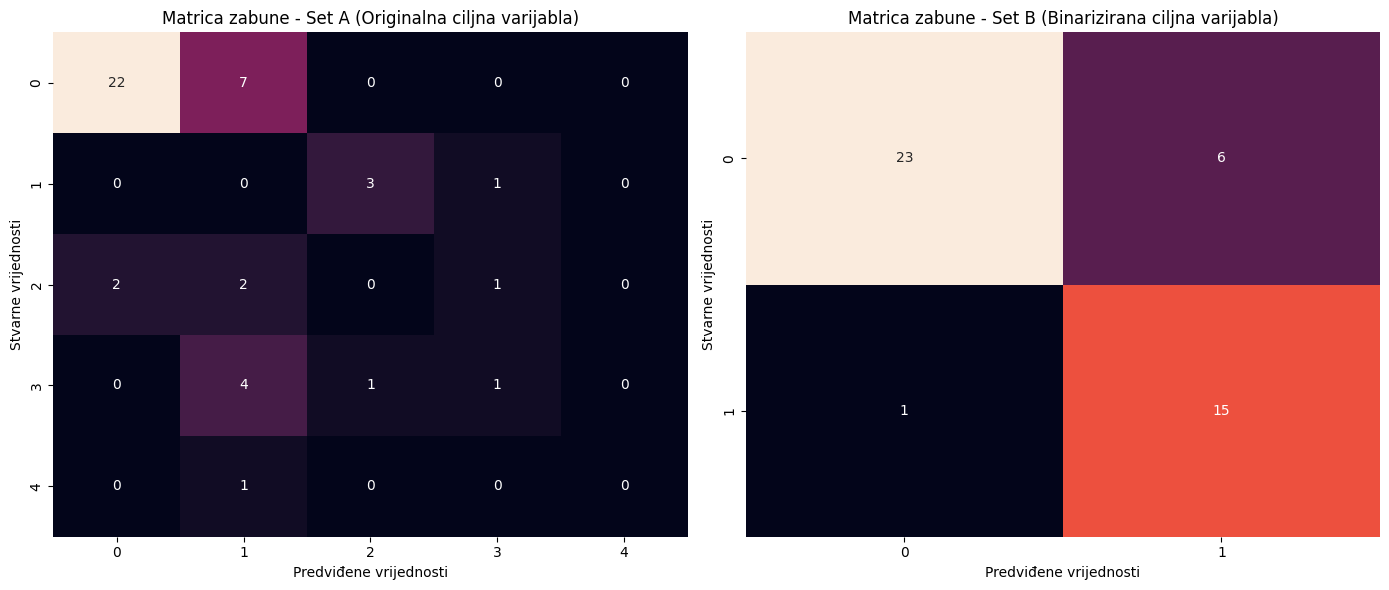

In [46]:
# Inicijalizacija modela s radijalnom baznom jezgrenom funkcijom
param_grid = {
    'C': [0.01, 0.1, 1, 10, 100]
}
model_rbf_C_1 = SVC(kernel='rbf')
model_rbf_C_2 = SVC(kernel='rbf')
grid_search_1 = GridSearchCV(estimator=model_rbf_C_1, param_grid=param_grid, cv=5, scoring='f1_weighted', n_jobs=-1)
grid_search_2 = GridSearchCV(estimator=model_rbf_C_2, param_grid=param_grid, cv=5, scoring='f1_weighted', n_jobs=-1)

# Treniranje modela na originalnim podacima (set A)
grid_search_1.fit(X_train3, y_train3)
best_model_1 = grid_search_1.best_estimator_
y_pred_rbf_C_1 = best_model_1.predict(X_test3)
report_rbf_C_1 = classification_report(y_test3, y_pred_rbf_C_1)

# Treniranje modela na binarnim podacima (set B)
grid_search_2.fit(X_train4, y_train4)
best_model_2 = grid_search_2.best_estimator_
y_pred_rbf_C_2 = best_model_2.predict(X_test4)
report_rbf_C_2 = classification_report(y_test4, y_pred_rbf_C_2)

# Ispis izvještaja
print(f"SVM s radijalnom baznom jezgrenom funkcijom (C={grid_search_1.best_params_['C']}) - SET A\n\n {report_rbf_C_1}\n\n")
print(f"SVM s radijalnom baznom jezgrenom funkcijom (C={grid_search_2.best_params_['C']}) - SET B\n\n {report_rbf_C_2}\n\n")

# Matrice zabune za oba seta
cm_rbf_C_1 = confusion_matrix(y_test3, y_pred_rbf_C_1)
cm_rbf_C_2 = confusion_matrix(y_test4, y_pred_rbf_C_2)

# Postavka za subplots (dva reda)
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Plot matrice zabune za Set A
sns.heatmap(cm_rbf_C_1, annot=True, fmt='d', cbar=False, ax=axes[0])
axes[0].set_title('Matrica zabune - Set A (Originalna ciljna varijabla)')
axes[0].set_xlabel('Predviđene vrijednosti')
axes[0].set_ylabel('Stvarne vrijednosti')

# Plot matrice zabune za Set B
sns.heatmap(cm_rbf_C_2, annot=True, fmt='d', cbar=False, ax=axes[1])
axes[1].set_title('Matrica zabune - Set B (Binarizirana ciljna varijabla)')
axes[1].set_xlabel('Predviđene vrijednosti')
axes[1].set_ylabel('Stvarne vrijednosti')

plt.tight_layout()
plt.show()


Korištenjem L2 regularizacije na setu A dobivamo lošije rezultate. Korištenjem L2 regularizacije s parametrom C=0.1 na set B uspjeli smo dobiti jednake rezultate. 

##### Usporedba jezgrenih funkcija

Usporedbom različitih vrijednosti parametra C i različitih jezgrenih funkcija SVMa zaključili smo da na setu A najbolje funkcionira linearna jezgrena funkcija, dok na setu B najbolje funkcionira radijalna bazna jezgrena funkcija.

### Poboljšanja u odnosu na članak

- Članak koristi značajku 'num' kao Target varijablu kojom izražava postoji li vjerojatnost zatajenja srca gdje vrijednošću 0 označavaju da ne postoji, te vrijednošću 1 da postoji vjerojatnost zatajenja srca. Gledajući skup podataka primijetili smo da takav pristup nije ispravan. Značajka 'num' sadrži vrijednosti od 0 do 4, što znači da članak nije ispravan te bi stvarne vrijednosti trebale biti npr. vrijednost 0 = vrlo mala vjerojatnost, 1 = mala vjerojatnost, 2 = umjerena vjerojatnost, 3 = velika vjerojatnost i 4 = vrlo velika vjerojatnost zatajenja srca. Za usporedbu napravili smo oba principa, gdje smo pretpostavili da sve vrijednosti koje nisu 0 klasificiramo kao 1.

- Članak koristi podjelu na skup za treniranje i skup za testiranje u odnosu 90% naprema 10%, dok smo se mi odlučili za 85% naprema 15% jer nam takva podjela daje 15 primjera više u skupu za testiranje čime dobivamo precizniju evaluaciju modela.

- Članak kao mjeru performanse koristi samo točnost (engl. accuracy), dok mi uz točnost računamo preciznost (engl. precision), odziv/osjetljivost (engl. recall) i F1 score kako bi bolje prikazali performanse modela. Uporaba matrice zabune dobar je vizualni prikaz performansi modela, s obzirom da točnost može biti zavaravajuća u situacijama poput ovdje gdje imamo mnogo primjera jedne klase, pa ukoliko model sve primjere klasificira kao tu klasu, točnost će djelovati velikom, dok u realnosti model neće imati stvarne rezultate, što iz članka nije bilo vidljivo, dok kod nas je.

- Također, u skupu podataka primijetili smo da članak koristi samo vrijednost 'Cleveland' značajke 'dataset', a nije naveden razlog zašto se ostale značajke ne koriste. Promatranjem podataka za ostale vrijednosti značajke 'dataset' primijetili smo da podaci za značajku 'Hungary' postiže samo vrijednosti 0 i 1 značajke 'num', što nije u skladu s ostatkom skupa podataka. Za ostale vrijednosti značajke koje nisu 'Cleveland' postoji puno nedostajućih vrijednosti, pa smo stoga odlučili limitirati na vrijednost 'Cleveland' značajke 'dataset', s obzirom da smo primijetili nesklad u skupljenim podacima za različite vrijednosti značajke 'dataset'.